# Preprocessing Dataset Ulasan E-Commerce Bahasa Indonesia

**Nama:** Mahyu Rijal  
**NIM:** 25146025  
**Dataset:** [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

Notebook ini memuat pemuatan dataset, eksplorasi data, distribusi label, preprocessing, serta 10 contoh teks sebelum dan sesudah preprocessing.


In [1]:
# Instalasi library (jalankan jika belum tersedia)
!pip -q install datasets pandas nltk Sastrawi matplotlib

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from datasets import load_dataset
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from nltk.tokenize import wordpunct_tokenize

nltk.download('stopwords')
from nltk.corpus import stopwords

print("Library berhasil diimpor")

Library berhasil diimpor


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 1. Memuat dataset

In [3]:
# Memuat split train dari Hugging Face
dataset = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print(dataset)

df = dataset["train"].to_pandas()
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})
Jumlah baris dan kolom: (11606, 3)


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


## 2. Informasi dataset dan distribusi sentimen

Jumlah data: 11606
Nama kolom: ['review', 'translate', 'sentimen']
\nInformasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB
\nJumlah nilai kosong:


,0
review,0
translate,0
sentimen,0


,Jumlah,Persentase (%)
sentimen,,
Negatif (0),5803,50.0
Positif (1),5803,50.0


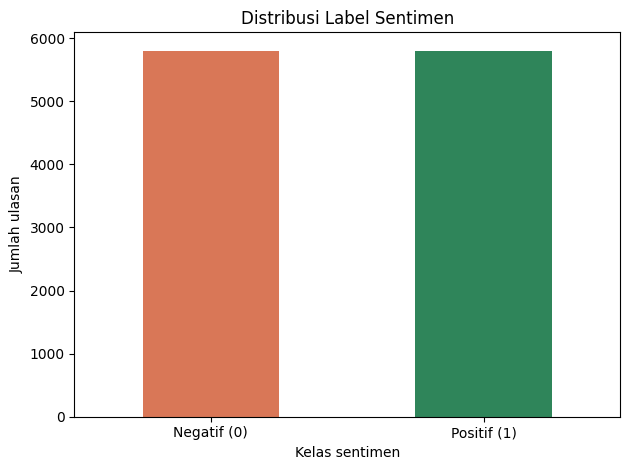

In [4]:
print("Jumlah data:", len(df))
print("Nama kolom:", df.columns.tolist())
print("\\nInformasi tipe data:")
df.info()

print("\\nJumlah nilai kosong:")
display(df.isna().sum())

# Label 0 = negatif, 1 = positif
distribusi = df["sentimen"].value_counts().sort_index()
ringkasan = pd.DataFrame({
    "Jumlah": distribusi,
    "Persentase (%)": (distribusi / len(df) * 100).round(2)
})
ringkasan.index = ringkasan.index.map({0: "Negatif (0)", 1: "Positif (1)"})
display(ringkasan)

ax = distribusi.rename(index={0:"Negatif (0)", 1:"Positif (1)"}).plot(
    kind="bar", color=["#d97757", "#2f855a"], rot=0
)
ax.set_title("Distribusi Label Sentimen")
ax.set_xlabel("Kelas sentimen")
ax.set_ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

## 3. Preprocessing teks

Tahapan yang dilakukan:
1. **Case folding:** mengubah seluruh huruf menjadi huruf kecil.
2. **Cleaning:** menghapus URL, angka, tanda baca, dan karakter khusus.
3. **Tokenisasi:** memecah kalimat menjadi token/kata.
4. **Stopword removal:** menghapus kata umum yang kurang informatif. Kata negasi seperti *tidak*, *bukan*, dan *belum* dipertahankan karena penting untuk sentimen.
5. **Stemming:** mengubah kata berimbuhan ke bentuk dasar menggunakan Sastrawi.


In [5]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_factory = StopWordRemoverFactory()
stopword_sastrawi = set(stop_factory.get_stop_words())
stopword_nltk = set(stopwords.words("indonesian"))
stop_words = stopword_sastrawi.union(stopword_nltk)

# Pertahankan kata negasi agar makna sentimen tidak berubah
negasi = {"tidak", "bukan", "belum", "jangan", "tanpa"}
stop_words = stop_words - negasi

def case_folding(teks):
    return str(teks).lower()

def cleaning(teks):
    teks = re.sub(r"https?://\\S+|www\\.\\S+", " ", teks)
    teks = re.sub(r"\\d+", " ", teks)
    teks = re.sub(r"[^a-zA-Z\\s]", " ", teks)
    teks = re.sub(r"\\s+", " ", teks).strip()
    return teks

def tokenisasi(teks):
    return wordpunct_tokenize(teks)

def stopword_removal(tokens):
    return [kata for kata in tokens if kata not in stop_words]

def stemming(tokens):
    return [stemmer.stem(kata) for kata in tokens]

def preprocess_text(teks):
    teks = case_folding(teks)
    teks = cleaning(teks)
    tokens = tokenisasi(teks)
    tokens = stopword_removal(tokens)
    tokens = stemming(tokens)
    return " ".join(tokens)

# Terapkan pada kolom review; isi kosong ditangani agar tidak menyebabkan error
df["review_preprocessed"] = df["review"].fillna("").apply(preprocess_text)
display(df[["review", "review_preprocessed", "sentimen"]].head(10))

,review,review_preprocessed,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...,0
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati,0
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging penyot r...,0
5,"Produk ini original, Dan kualitasnya sangat ba...",produk original kualitas cepat kirim sanagt ce...,1
6,kualitas sangat jelek. bocor,kualitas jelek bocor,0
7,"terimakasih banyak ka ya, barang sudah diterim...",terimakasih ka barang terima sukses ka,1
8,"Body nya lebih berat dari cm 1579, spiral nya ...",body nya berat cm spiral nya tipis banding cm ...,0
9,pesanan di terima tanggal 27 January 2021 teta...,pesan terima tanggal january buka pagi tanggal...,0


## 4. Menampilkan 10 contoh sebelum dan sesudah preprocessing

In [8]:
contoh = df[["review", "review_preprocessed", "sentimen"]].head(10).copy()

contoh.columns = [
    "Teks sebelum preprocessing",
    "Teks sesudah preprocessing",
    "Label sentimen"
]

display(contoh)

,Teks sebelum preprocessing,Teks sesudah preprocessing,Label sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...,0
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati,0
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging penyot r...,0
5,"Produk ini original, Dan kualitasnya sangat ba...",produk original kualitas cepat kirim sanagt ce...,1
6,kualitas sangat jelek. bocor,kualitas jelek bocor,0
7,"terimakasih banyak ka ya, barang sudah diterim...",terimakasih ka barang terima sukses ka,1
8,"Body nya lebih berat dari cm 1579, spiral nya ...",body nya berat cm spiral nya tipis banding cm ...,0
9,pesanan di terima tanggal 27 January 2021 teta...,pesan terima tanggal january buka pagi tanggal...,0


## 5. Menyimpan hasil preprocessing (opsional)

File CSV dapat digunakan untuk tahap analisis atau pemodelan sentimen berikutnya.


In [7]:
df.to_csv("hasil_preprocessing_sentimen.csv", index=False, encoding="utf-8-sig")
print("File hasil_preprocessing_sentimen.csv berhasil disimpan")

File hasil_preprocessing_sentimen.csv berhasil disimpan


## 6. Kesimpulan

Preprocessing membuat teks lebih seragam dan mengurangi gangguan berupa URL, angka, tanda baca, karakter khusus, serta kata umum yang kurang relevan. Tokenisasi memudahkan pengolahan kata, sedangkan stemming menyatukan variasi kata berimbuhan ke bentuk dasarnya. Tahapan ini dapat membantu mengurangi variasi fitur dan meningkatkan kualitas masukan untuk analisis sentimen. Namun, penghapusan kata harus dilakukan hati-hati karena kata negasi dapat mengubah makna sentimen.